# F-JEPA : autoencodeur masqué qui prédit les jours suivants (données SYNTHÉTIQUES)

> ⚠️ **Données inventées** (voir `generation_capteurs_4ans.ipynb`, sections 8 et 9). Rien ici ne démontre quoi que ce soit sur les machines réelles.

**Demande d'Antoine (21/10/2026)** : « Fais l'entraînement pour le futur avec le MAE ».

**Contexte.** Dans `F-JEPA_jepa_futur`, JEPA pré-entraîné à prédire les **représentations latentes** des 2 jours suivants à partir des 3 jours passés (JEPA-futur) a fait moins bien que JEPA à blocs intérieurs (JEPA-16) et même que l'encodeur aléatoire. Ici, même tâche de prédiction du futur, mais avec la cible de l'**autoencodeur masqué** : reconstruire les **tokens bruts** des 2 jours suivants (**AE-futur**). Tout le reste est identique à JEPA-futur (encodeur, prédicteur, exemples, nombre de pas, fine-tuning, sonde, test).

Les fine-tunings et sondes de l'encodeur aléatoire, de JEPA-16, de l'autoencodeur-16 (blocs intérieurs) et de JEPA-futur sont repris de `results_600/` et `results_jepa_futur/` ; le boosting expert est réentraîné à l'identique.

**Hypothèses, écrites avant l'exécution** (test M1–M16, 600 événements) :
- **H22.** AE-futur fine-tuné bat JEPA-futur fine-tuné en moyenne des 3 graines, au fine-tuning normal et au fine-tuning long.
- **H23.** AE-futur fine-tuné bat l'encodeur aléatoire fine-tuné pour chaque graine (fine-tuning normal).
- **H24.** La sonde sur AE-futur gelé bat la sonde sur JEPA-futur gelé et la sonde sur l'encodeur aléatoire gelé (moyenne des graines).
- **H25.** AE-futur fine-tuné bat l'autoencodeur-16 (blocs intérieurs) fine-tuné en moyenne des graines (fine-tuning normal).
- **H26.** Sans étiquette, la « surprise » d'AE-futur (erreur de prévision des 2 derniers jours) a une ROC-AUC d'au moins 0,55.

**Plan** : 0. paramètres · 1. 600 événements · 2. tokens · 3. cible · 4. baseline experte · 5. pré-entraînement AE-futur · 6. fine-tuning · 7. sondes · 8. surprise · 9. résultats · 10. hypothèses et conclusions

## 0. Paramètres

In [1]:
import os, time, json, math, warnings, pickle
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.signal import lfilter
import torch, torch.nn as nn, torch.nn.functional as F
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
warnings.filterwarnings("ignore", message="enable_nested_tensor")
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

DATA_DIR = Path(os.environ.get("FJEPA_DATA", "../input/capteurs_4ans"))
FLOTTE_DIR, ETENDUE_DIR = DATA_DIR / "flotte_non_etiquetee", DATA_DIR / "flotte_etendue"
RES = Path(os.environ.get("FJEPA_RES", "results_mae_futur")); RES.mkdir(exist_ok=True)
RES_JF = Path(os.environ.get("FJEPA_RES_JF", "results_jepa_futur"))   # JEPA-futur : poids, fine-tunings et sondes (notebook F-JEPA_jepa_futur)
RES_600 = Path(os.environ.get("FJEPA_RES_600", "results_600"))      # fine-tunings et sondes déjà calculés (aléatoire, JEPA-16, autoencodeur-16)
SEEDS = [int(x) for x in os.environ.get("FJEPA_SEEDS", "0,1,2").split(",")]
FT_EPOCHS, FT_STEPS = 6, 150                      # mêmes réglages que les fine-tunings repris
FT_STEPS_LONG = 2 * FT_STEPS                      # fine-tuning 2 fois plus long (le meilleur réglage de F-JEPA_600_evenements)
N_DECL = int(os.environ.get("FJEPA_N_DECL", "600"))
OLD_NAMES = ["Aléatoire", "JEPA-16", "Autoencodeur-16"]     # repris de results_600 (mêmes graines, même code)
JF = "JEPA-futur"                                          # repris de results_jepa_futur
NEW = "AE-futur"                                           # le nouvel encodeur
# pré-entraînement « jours suivants » (identique à JEPA-futur)
CTX_DAYS, FUT_DAYS, SEG = 3, 2, 8   # 3 jours de contexte -> 2 jours suivants ; résumé latent toutes les 2 h (8 tokens)
PRE_EPOCHS, PRE_STEPS, PRE_B = int(os.environ.get("FJEPA_PRE_EPOCHS", "20")), 200, 48   # 20 × 200 pas comme JEPA-16 ; 48 exemples = 144 jours de contexte par lot
CONFIG_PRE = dict(ctx=CTX_DAYS, fut=FUT_DAYS, seg=SEG, epochs=PRE_EPOCHS, steps=PRE_STEPS, batch=PRE_B)
CONFIG_FT = dict(ft_epochs=FT_EPOCHS, batch=128)

CH = ["speed", "temp_ambiante_c", "temp_moteur_c", "temp_palier_c", "vibration_mm_s", "courant_a", "pression_bar"]
SENS = ["temp_moteur_c", "temp_palier_c", "vibration_mm_s", "courant_a", "pression_bar"]
TYPES = ["refroidissement", "roulement", "courroie", "pneumatique", "electrique"]
TOKM, WIN, STRIDE = 15, 96, 8      # token = 15 min ; fenêtre = 24 h ; une prédiction toutes les 2 h
HOR = 7 * 1440; POST_REPAIR = 2 * 1440; MIN_RUN = 120
TRAIN_END, VAL_END = pd.Timestamp("2024-09-01"), pd.Timestamp("2025-09-01")
MACH = ["M1", "M2", "M3", "M4"]; M16 = [f"M{k}" for k in range(1, 17)]
torch.set_num_threads(os.cpu_count())
t_start = time.time()
print("Données :", DATA_DIR, "| résultats :", RES)

Données : /mnt/project-files/donnees_capteurs_4ans | résultats : results_mae_futur


## 1. Vérité terrain et choix des 600 événements déclarés

Les événements sont déclarés dans l'ordre des machines (M1, M2, …, M40), tous ceux de la période d'entraînement, jusqu'à en avoir exactement 600. On ne charge ensuite que les machines nécessaires.

In [2]:
cols = ["machine", "type", "issue", "debut_degradation", "evenement", "fin_intervention"]
deg = pd.concat([pd.read_csv(DATA_DIR / "verite_terrain_degradations.csv", parse_dates=cols[3:])[cols],
                 pd.read_csv(FLOTTE_DIR / "verite_terrain_flotte.csv", parse_dates=cols[3:])[cols],
                 pd.read_csv(ETENDUE_DIR / "verite_terrain_flotte_etendue.csv", parse_dates=cols[3:])[cols]], ignore_index=True)
deg["num"] = deg.machine.str[1:].astype(int)
ev = deg[deg.issue != "preventif"].sort_values(["num", "evenement"])
ev_tr = ev[ev.evenement < TRAIN_END]
cum = ev_tr.groupby("num").size().cumsum()
K = int(cum.index[np.searchsorted(cum.to_numpy(), N_DECL)])           # dernière machine (partiellement) déclarée
ALL = [f"M{k}" for k in range(1, K + 1)]
n_avant = int(cum.loc[K - 1]); n_K = N_DECL - n_avant
evK = ev_tr[ev_tr.num == K].evenement.sort_values().to_numpy()
DECL_FIN = pd.Timestamp(evK[n_K]) - pd.Timedelta(minutes=HOR) if n_K < len(evK) else TRAIN_END   # fenêtres de M{K} gardées avant cette date
DECL = {"600": (ALL, DECL_FIN)}
assert int(cum.loc[4]) == 62 and int(cum.loc[16]) == 262
print(f"600 événements = M1 à M{K - 1} ({n_avant}) + {n_K} des {len(evK)} de M{K} (fenêtres d'entraînement de M{K} gardées jusqu'au {DECL_FIN:%d/%m/%Y})")
tab = ev.assign(periode=np.where(ev.evenement < TRAIN_END, "entraînement", np.where(ev.evenement < VAL_END, "validation", "test")),
                groupe=pd.cut(ev.num, [0, 4, 16, K, 99], labels=["M1–M4", "M5–M16", f"M17–M{K}", f"M{K + 1}–M40 (non utilisées)"])
                ).groupby(["groupe", "periode"], observed=False).size().unstack()[["entraînement", "validation", "test"]]
tab

600 événements = M1 à M36 (589) + 11 des 13 de M37 (fenêtres d'entraînement de M37 gardées jusqu'au 15/07/2024)


periode,entraînement,validation,test
groupe,,,
M1–M4,62,35,36
M5–M16,200,103,106
M17–M37,340,160,167
M38–M40 (non utilisées),54,26,23


## 2. Tokens et caractéristiques expertes

Identiques aux notebooks précédents, machine par machine (≈ 1 min par machine).

In [3]:
USE = ["timestamp", "running"] + CH
def load(m):
    k = int(m[1:]); d = DATA_DIR if k <= 4 else (FLOTTE_DIR if k <= 16 else ETENDUE_DIR)
    return pd.concat([pd.read_csv(d / f"capteurs_{m}_{y}-{y + 1}.csv.gz", parse_dates=["timestamp"], usecols=USE) for y in range(2022, 2026)], ignore_index=True)

def tokenize(r):
    X = r[CH].to_numpy(np.float32); n = len(X) // TOKM
    tr = (r.timestamp < TRAIN_END).to_numpy()
    med = np.nanmedian(X[tr], 0); iqr = np.nanpercentile(X[tr], 75, 0) - np.nanpercentile(X[tr], 25, 0)
    iqr = np.where(iqr < 1e-3, np.nanstd(X[tr], 0), iqr)
    Z = np.clip((X - med) / iqr, -8, 8)[:n * TOKM].reshape(n, TOKM, len(CH)).transpose(0, 2, 1)
    miss = np.isnan(Z); mu = np.nanmean(Z, 2, keepdims=True); sd = np.nanstd(Z, 2, keepdims=True)
    shape = np.clip((Z - mu) / (sd + 0.01), -4, 4); shape[miss] = 0; mu = np.nan_to_num(mu); sd = np.nan_to_num(sd)
    tok = np.concatenate([mu[..., 0], np.log(sd[..., 0] + 0.01), shape.reshape(n, -1), miss.mean(2)], 1).astype(np.float32)
    run = r.running.to_numpy()[:n * TOKM].reshape(n, TOKM).mean(1).astype(np.float32)
    return tok, run

def lowpass(x, tau): a = math.exp(-1 / tau); return lfilter([1 - a], [1, -a], x)
def phys_features(r):
    sp = r.speed.to_numpy(float); run = r.running.to_numpy(float)
    feats = [np.exp(-0.5 * ((sp - c) / 0.12) ** 2) for c in np.linspace(0.3, 1.3, 9)]
    feats += [lowpass(sp, t) for t in (5, 15, 30, 60, 120)] + [lowpass(sp, t) ** 2 for t in (15, 60)]
    feats += [lowpass(run, t) for t in (5, 30, 120)] + [run, r.temp_ambiante_c.ffill().bfill().to_numpy()]
    return np.stack(feats, 1).astype(np.float32)

def token_features(r, NTOK):
    run = r.running.to_numpy()[:NTOK * TOKM].reshape(NTOK, TOKM)
    Xf = phys_features(r)[:NTOK * TOKM]; trm = (r.timestamp < TRAIN_END).to_numpy()[:NTOK * TOKM]
    out = {"run": run.mean(1)}
    for c in SENS:
        x = r[c].to_numpy(float)[:NTOK * TOKM]; ok = ~np.isnan(x)
        fit = trm & ok & ((run.ravel() == 1) if c != "pression_bar" else True)
        idx = np.random.default_rng(0).choice(np.flatnonzero(fit), min(400_000, fit.sum()), replace=False)
        reg = Ridge(alpha=1.0).fit(Xf[idx], x[idx])
        res = np.where(ok, x - reg.predict(Xf), np.nan).reshape(NTOK, TOKM)
        xt = x.reshape(NTOK, TOKM); w = run if c != "pression_bar" else np.ones_like(run)
        out[f"{c}_moy"] = np.nansum(np.where(w == 1, xt, 0), 1) / np.maximum(w.sum(1), 1)
        out[f"{c}_res_moy"] = np.nanmean(res, 1); out[f"{c}_res_ec"] = np.nanstd(res, 1)
        dct = xt - np.nanmean(xt, 1, keepdims=True); den = np.nansum(dct ** 2, 1) + 1e-9
        for L_ in (1, 2, 4, 8): out[f"{c}_ac{L_}"] = np.nansum(dct[:, L_:] * dct[:, :-L_], 1) / den
    dI = np.diff(r.courant_a.to_numpy(float)[:NTOK * TOKM].reshape(NTOK, TOKM), axis=1)
    dV = np.diff(r.vibration_mm_s.to_numpy(float)[:NTOK * TOKM].reshape(NTOK, TOKM), axis=1)
    out["corr_dI_dV"] = np.nansum(dI * dV, 1) / np.sqrt(np.nansum(dI ** 2, 1) * np.nansum(dV ** 2, 1) + 1e-9)
    return pd.DataFrame(out)

TOK, RUN, TOKF, RUNMIN = {}, {}, {}, {}
for m in ALL:
    r = load(m)
    if m == "M1": T0 = r.timestamp.iloc[0]; N = len(r)
    assert len(r) == N and r.timestamp.iloc[0] == T0 and (r.timestamp.diff().dropna() == pd.Timedelta("1min")).all()
    TOK[m], RUN[m] = tokenize(r); NTOK = len(TOK[m])
    TOKF[m] = token_features(r, NTOK)
    RUNMIN[m] = np.r_[0, np.cumsum(r.running.to_numpy())]        # minutes de marche cumulées (pour l'exclusion des fenêtres)
    del r
    if m in ("M1", "M16") or m == ALL[-1] or int(m[1:]) % 8 == 0: print(f"{m} : {time.time() - t_start:.0f} s", flush=True)
D_TOK = TOK["M1"].shape[1]

M1 : 15 s


M8 : 93 s


M16 : 183 s


M24 : 272 s


M32 : 365 s


M37 : 419 s


## 3. Cible et jeux d'étiquettes

Mêmes fenêtres, même cible, mêmes exclusions qu'avant. Un seul jeu d'étiquettes d'entraînement (600 événements déclarés) ; la validation se fait sur les mêmes machines que l'entraînement (période sept. 2024 → août 2025) et ne sert qu'à choisir les réglages et l'époque, de la même façon pour toutes les méthodes.

In [4]:
rows = []
for m in ALL:
    d = deg[deg.machine == m]; run_cum = RUNMIN[m]
    excl = np.zeros(N + 1, bool)
    for _, f in d.iterrows():
        a = int((f.debut_degradation - T0).total_seconds() // 60); e = int((f.evenement - T0).total_seconds() // 60)
        b = int((f.fin_intervention - T0).total_seconds() // 60) + POST_REPAIR
        if f.issue == "preventif": excl[a:b] = True
        else: excl[e:b] = True
    evm = ev[ev.machine == m]
    evt = ((evm.evenement - T0).dt.total_seconds() // 60).astype(int).to_numpy()
    for e_tok in range(WIN, NTOK + 1, STRIDE):
        t = e_tok * TOKM; j = np.searchsorted(evt, t, side="right")
        dt = evt[j] - t if j < len(evt) else 10 ** 9
        rows.append(dict(machine=m, tok_end=e_tok, t=t, y=int(dt <= HOR), type_suivant=evm.type.iloc[j] if j < len(evt) else "", t_evt=evt[j] if j < len(evt) else -1,
                         marche_min=run_cum[t] - run_cum[t - WIN * TOKM], exclu=excl[t - 1]))
S = pd.DataFrame(rows); del rows
S["time"] = T0 + pd.to_timedelta(S.t, unit="min")
S["split"] = np.where(S.time < TRAIN_END, "train", np.where(S.time < VAL_END, "val", "test"))
S["eval"] = (~S.exclu) & (S.marche_min >= MIN_RUN)
E = S[S["eval"]].copy()
ref = (S.split == "train") & (S.marche_min >= MIN_RUN)        # référence de normalisation, sans étiquette
yE = E.y.to_numpy(); in4 = E.machine.isin(MACH).to_numpy(); in16 = E.machine.isin(M16).to_numpy()
assert in4.sum() == 43940 and in16.sum() == 177799, "les fenêtres de M1–M16 doivent être celles des notebooks précédents"
assert (np.flatnonzero(in16) == np.arange(in16.sum())).all()       # M1–M16 en tête, dans le même ordre (reprise des scores)
TR, VA = {}, {}
for k, (machines, fin) in DECL.items():
    TR[k] = ((E.split == "train") & E.machine.isin(machines)).to_numpy()
    if fin is not None: TR[k] = TR[k] & ~((E.machine == ALL[-1]) & (E.time >= fin)).to_numpy()
    VA[k] = ((E.split == "val") & E.machine.isin(machines)).to_numpy()
TE = {"M1–M4": ((E.split == "test") & in4).to_numpy(), "M1–M16": ((E.split == "test") & in16).to_numpy(), f"M1–M{K}": (E.split == "test").to_numpy()}
TALL = f"M1–M{K}"
lab = []
for k in DECL:
    pos = E[TR[k] & (yE == 1)]
    lab.append(dict(etiquettes=f"{k} événements déclarés", machines=f"M1–M{len(DECL[k][0])}", evenements_avec_fenetre_positive=pos.groupby(["machine", "t_evt"]).ngroups,
                    fenetres=TR[k].sum(), fenetres_positives=len(pos), **{f"pos_{t}": (pos.type_suivant == t).sum() for t in TYPES}))
for k, msk in TE.items():
    pos = E[msk & (yE == 1)]
    lab.append(dict(etiquettes=f"(test {k})", machines="", evenements_avec_fenetre_positive=pos.groupby(["machine", "t_evt"]).ngroups, fenetres=msk.sum(),
                    fenetres_positives=len(pos), **{f"pos_{t}": (pos.type_suivant == t).sum() for t in TYPES}))
LAB = pd.DataFrame(lab).set_index("etiquettes")
LAB

,machines,evenements_avec_fenetre_positive,fenetres,fenetres_positives,pos_refroidissement,pos_roulement,pos_courroie,pos_pneumatique,pos_electrique
etiquettes,,,,,,,,,
600 événements déclarés,M1–M37,555,205943,35790,8199,8557,6012,8106,4916
(test M1–M4),,35,10636,2133,462,323,398,560,390
(test M1–M16),,131,43854,8067,1962,1510,1486,1610,1499
(test M1–M37),,285,101000,17801,4634,3700,3014,3534,2919


Un événement « déclaré » n'a pas toujours de fenêtre positive évaluée (machine trop peu en marche dans les 24 h, ou fenêtres retirées après une autre intervention), d'où une colonne `evenements_avec_fenetre_positive` un peu plus petite que 600.

## 4. Baseline experte (boosting et logistique sur caractéristiques)

Réentraînée ici (rapide), identique à `F-JEPA_600_evenements`.

In [5]:
def window_features(m):
    f = TOKF[m]; s = S[S.machine == m]; run_tok = f.run.to_numpy(); good = run_tok >= 0.8
    cols_lvl = [f"{c}_moy" for c in SENS]; cols_dyn = [c for c in f.columns if c not in cols_lvl + ["run"]]
    e = s.tok_end.to_numpy(); b = e - WIN; out = {}
    cs_w = np.r_[0, np.cumsum(run_tok)]; wsum = cs_w[e] - cs_w[b]
    cs = np.vstack([np.zeros((1, len(cols_lvl))), np.cumsum(f[cols_lvl].fillna(0).to_numpy() * run_tok[:, None], 0)])
    for i, c in enumerate(cols_lvl): out[c] = (cs[e, i] - cs[b, i]) / np.maximum(wsum, 1e-6)
    dyn = f[cols_dyn].to_numpy(); valid = good[:, None] & ~np.isnan(dyn)
    csd = np.vstack([np.zeros((1, len(cols_dyn))), np.cumsum(np.where(valid, dyn, 0), 0)])
    csn = np.vstack([np.zeros((1, len(cols_dyn))), np.cumsum(valid, 0)])
    for i, c in enumerate(cols_dyn):
        n_ = csn[e, i] - csn[b, i]; out[c] = np.where(n_ > 0, (csd[e, i] - csd[b, i]) / np.maximum(n_, 1), np.nan)
    out["marche_frac"] = wsum / WIN
    return pd.DataFrame(out, index=s.index)

def zscore_per_machine(df, ref_mask):
    out = df.copy()
    for m in ALL:
        mm = S.machine == m; mu = df[mm & ref_mask].mean(); sd = df[mm & ref_mask].std() + 1e-9
        out.loc[mm] = (df[mm] - mu) / sd
    return out
def ewm_per_machine(df, span):
    return pd.concat([df[S.machine == m].ewm(span=span, ignore_na=True).mean() for m in ALL]).loc[df.index]

WF = pd.concat([window_features(m) for m in ALL]).loc[S.index]
WFZ = zscore_per_machine(WF, ref)
XF = pd.concat([WFZ, ewm_per_machine(WFZ, 12).add_suffix("_l24h")], axis=1).loc[E.index].fillna(0).to_numpy()
del TOKF


def fit_select(grid, X, tr, va):
    best = None
    for name, mk in grid:
        mdl = mk().fit(X[tr], yE[tr]); auc = roc_auc_score(yE[va], mdl.predict_proba(X[va])[:, 1])
        if best is None or auc > best[0]: best = (auc, name, mdl)
    return best[2].predict_proba(X)[:, 1], best[1], best[0]

gbm_grid = [(f"lr={lr}, feuilles={ml}", (lambda lr=lr, ml=ml: HistGradientBoostingClassifier(learning_rate=lr, max_leaf_nodes=ml, max_iter=300, l2_regularization=1.0, random_state=0)))
            for lr in (0.03, 0.1) for ml in (15, 31)]
lr_grid = [(f"C={C}", (lambda C=C: make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=2000)))) for C in (0.01, 0.1, 1.0)]

SCORES = {}      # (méthode, étiquettes "600", graine ou None) -> score sur E
for k in DECL:
    for nm, grid in [("Boosting experts", gbm_grid), ("Logistique experts", lr_grid)]:
        p, hp, a = fit_select(grid, XF, TR[k], VA[k]); SCORES[(nm, k, None)] = p
        print(f"{k:>3} événements  {nm:<20} {hp:<22} AUC validation {a:.3f}", flush=True)
print(f"({time.time() - t_start:.0f} s)")

600 événements  Boosting experts     lr=0.03, feuilles=15   AUC validation 0.758


600 événements  Logistique experts   C=0.1                  AUC validation 0.744


(497 s)


## 5. Pré-entraînements « futur » : 3 jours de contexte → 2 jours suivants

Un exemple = 5 jours consécutifs de la période d'entraînement d'une machine de M1–M16 (aucune étiquette), chacun avec au moins 2 h de marche. Les 3 premiers passent dans l'encodeur (avec gradient) ; chaque jour est résumé en 12 vecteurs (moyenne par tranche de 2 h). Le prédicteur reçoit les 36 résumés du contexte plus 24 requêtes (une par tranche de 2 h future, avec sa position). Seule la cible diffère :

| | cible pour chaque tranche de 2 h des 2 jours suivants | perte | encodeur gardé |
|---|---|---|---|
| **JEPA-futur** (notebook `F-JEPA_jepa_futur`, poids relus) | représentation latente de l'encodeur cible (moyenne mobile), normalisée | Smooth L1 | encodeur cible |
| **AE-futur** (nouveau) | **tokens bruts** (moyenne, log-écart-type, forme, valeurs manquantes des 7 canaux), moyennés sur la tranche | erreur quadratique, comme l'autoencodeur-16 | encodeur |

Tout le reste est identique à JEPA-futur (même encodeur, même prédicteur avec une sortie de la taille d'un token, mêmes exemples tirés dans le même ordre, mêmes 20 × 200 pas, même optimiseur). C'est donc la comparaison « cible latente contre cible brute » pour la prédiction du futur, comme `F-JEPA_capteurs_4ans` l'avait faite pour les blocs intérieurs.

Contrôle : perte du prédicteur contre deux références naïves, **persistance** (le dernier jour de contexte recopié) et **moyenne** (la cible moyenne du lot), à l'entraînement et sur la période de validation (sept. 2024 → août 2025) de M1–M16.

In [6]:
class Encoder(nn.Module):
    def __init__(self, d_in, d=96, L=WIN, depth=4, heads=4):
        super().__init__()
        self.proj = nn.Linear(d_in, d); self.pos = nn.Parameter(torch.randn(1, L, d) * 0.02)
        self.mask_tok = nn.Parameter(torch.zeros(1, 1, d))
        layer = nn.TransformerEncoderLayer(d, heads, 2 * d, dropout=0.0, batch_first=True, norm_first=True)
        self.tr = nn.TransformerEncoder(layer, depth); self.norm = nn.LayerNorm(d)
    def forward(self, x, mask=None):
        h = self.proj(x)
        if mask is not None: h = torch.where(mask[..., None], self.mask_tok.expand_as(h), h)
        return self.norm(self.tr(h + self.pos))

N_CTX, N_FUT = CTX_DAYS * WIN // SEG, FUT_DAYS * WIN // SEG
class FuturePredictor(nn.Module):
    """lit les résumés 2 h des jours de contexte et prédit la cible des tranches de 2 h des jours suivants"""
    def __init__(self, d=96, d_out=96, depth=2, heads=4):
        super().__init__()
        self.inp = nn.Linear(d, d); self.pos = nn.Parameter(torch.randn(1, N_CTX + N_FUT, d) * 0.02)
        self.query = nn.Parameter(torch.zeros(1, 1, d))
        layer = nn.TransformerEncoderLayer(d, heads, 2 * d, dropout=0.0, batch_first=True, norm_first=True)
        self.tr = nn.TransformerEncoder(layer, depth); self.out = nn.Linear(d, d_out)
    def forward(self, ctx):
        h = torch.cat([self.inp(ctx), self.query.expand(len(ctx), N_FUT, -1)], 1) + self.pos
        return self.out(self.tr(h)[:, N_CTX:])

def seg_pool(z): return z.reshape(z.shape[0], WIN // SEG, SEG, z.shape[-1]).mean(2)      # (n, 96, d) -> (n, 12, d)
def tgt_rep(tgt, x): return seg_pool(F.layer_norm(tgt(x), (96,)))
def target_of(kind, tgt, x): return tgt_rep(tgt, x) if kind == "jepa" else seg_pool(x)       # cible latente ou tokens bruts
def crit(kind): return F.smooth_l1_loss if kind == "jepa" else F.mse_loss

TOKT = {m: torch.from_numpy(TOK[m]) for m in ALL}
RUNT = {m: torch.from_numpy(RUN[m]) for m in ALL}
def batch_from(idx): return torch.stack([TOKT[ALL[mi]][s:s + WIN] for mi, s in idx])
def batch_w(idx): return torch.stack([RUNT[ALL[mi]][s:s + WIN] for mi, s in idx])[..., None]
ND = CTX_DAYS + FUT_DAYS
def batch_days(idx): return torch.stack([TOKT[ALL[mi]][s:s + ND * WIN].reshape(ND, WIN, D_TOK) for mi, s in idx])   # (B, 5, 96, D)

def corpus_days(machines, t0, t1):
    """débuts possibles de 5 jours consécutifs dans [t0, t1[ (en tokens), chaque jour avec au moins 2 h de marche"""
    out = []
    for m in machines:
        csr = np.r_[0, np.cumsum(RUN[m])]; starts = np.arange(t0, t1 - ND * WIN)
        ok = np.ones(len(starts), bool)
        for k in range(ND): ok &= (csr[starts + (k + 1) * WIN] - csr[starts + k * WIN]) * TOKM >= MIN_RUN
        out += [(ALL.index(m), s) for s in starts[ok]]
    return np.array(out)
tok_of = lambda ts: int((ts - T0).total_seconds() // 60) // TOKM
PRE_F = corpus_days(M16, 0, tok_of(TRAIN_END))
VAL_F = corpus_days(M16, tok_of(TRAIN_END), tok_of(VAL_END))
print(f"corpus de pré-entraînement : {len(PRE_F):,} débuts possibles (M1–M16, sept. 2022 → août 2024) ; validation : {len(VAL_F):,}")

def losses(kind, enc, tgt, pred, x):
    """perte du prédicteur et des deux références naïves, pour un lot de 5 jours"""
    B = len(x); xc = x[:, :CTX_DAYS].reshape(-1, WIN, D_TOK); L = crit(kind)
    with torch.no_grad():
        target = target_of(kind, tgt, x[:, CTX_DAYS:].reshape(-1, WIN, D_TOK)).reshape(B, N_FUT, -1)
        last = target_of(kind, tgt, x[:, CTX_DAYS - 1]).repeat(1, FUT_DAYS, 1)
    p = pred(seg_pool(enc(xc)).reshape(B, N_CTX, -1))
    return (L(p, target), L(last, target).item(), L(target.mean(0, keepdim=True).expand_as(target), target).item(), target.std(0).mean().item())

def pretrain_ae_futur(seed, epochs=PRE_EPOCHS, steps=PRE_STEPS, B=PRE_B):
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    enc, pred = Encoder(D_TOK), FuturePredictor(d_out=D_TOK)
    opt = torch.optim.AdamW(list(enc.parameters()) + list(pred.parameters()), lr=5e-4, weight_decay=0.05)
    total = epochs * steps; sched = torch.optim.lr_scheduler.OneCycleLR(opt, 5e-4, total_steps=total, pct_start=0.1)
    hist = []
    for ep in range(epochs):
        acc = np.zeros(4)
        for _ in range(steps):
            loss, lp, lm, sd = losses("ae", enc, None, pred, batch_days(PRE_F[rng.integers(0, len(PRE_F), B)]))
            opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(enc.parameters(), 1.0); opt.step(); sched.step()
            acc += [loss.item(), lp, lm, sd]
        hist.append((acc / steps).tolist())
        if ep % 5 == 4 or ep == epochs - 1:
            print(f"  graine {seed}, époque {ep + 1}/{epochs} : perte {hist[-1][0]:.4f} | persistance {hist[-1][1]:.4f} | moyenne {hist[-1][2]:.4f}", flush=True)
    return {"enc": enc.state_dict(), "pred": pred.state_dict(), "config": CONFIG_PRE}, hist

def load_models(kind, st):
    enc, pred = Encoder(D_TOK), FuturePredictor(d_out=96 if kind == "jepa" else D_TOK)
    enc.load_state_dict(st["enc"]); pred.load_state_dict(st["pred"]); tgt = None
    if kind == "jepa": tgt = Encoder(D_TOK); tgt.load_state_dict(st["tgt"]); tgt.eval()
    enc.eval(); pred.eval(); return enc, tgt, pred

@torch.no_grad()
def eval_val(kind, st, n=3000, B=100):
    enc, tgt, pred = load_models(kind, st)
    sel = VAL_F[np.random.default_rng(123).choice(len(VAL_F), n, replace=False)]; acc = np.zeros(4)
    for i in range(0, n, B):
        l, lp, lm, sd = losses(kind, enc, tgt, pred, batch_days(sel[i:i + B])); acc += [l.item(), lp, lm, sd]
    return acc / (n // B)

STATES, HIST, PRE_ST, VALP = {}, {}, {}, []
KIND = {JF: "jepa", NEW: "ae"}
for s_ in SEEDS:
    st = torch.load(RES_JF / f"jepa_futur_seed{s_}.pt"); assert st["config"] == CONFIG_PRE, "JEPA-futur doit avoir les mêmes réglages"
    PRE_ST[(JF, s_)] = st; STATES[(JF, s_)] = st["tgt"]
    path = RES / f"ae_futur_seed{s_}.pt"; t1 = time.time()
    if path.exists() and torch.load(path).get("config") == CONFIG_PRE:
        st = torch.load(path); msg = "poids relus"
    else:
        st, HIST[s_] = pretrain_ae_futur(s_); torch.save(st, path); json.dump(HIST, open(RES / f"historique_seed{s_}.json", "w")); msg = "pré-entraîné"
    if s_ not in HIST and (RES / f"historique_seed{s_}.json").exists(): HIST[s_] = json.load(open(RES / f"historique_seed{s_}.json"))[str(s_)]
    PRE_ST[(NEW, s_)] = st; STATES[(NEW, s_)] = st["enc"]
    print(f"{NEW} graine {s_} : {msg} ({time.time() - t1:.0f} s)", flush=True)
    for name in (JF, NEW):
        v = eval_val(KIND[name], PRE_ST[(name, s_)])
        VALP.append(dict(modele=name, graine=s_, perte_predicteur=v[0], perte_persistance=v[1], perte_moyenne=v[2]))
for s_ in SEEDS: torch.manual_seed(1000 + s_); STATES[("Aléatoire", s_)] = Encoder(D_TOK).state_dict()
VALP = pd.DataFrame(VALP).set_index(["modele", "graine"]); VALP["gain_vs_persistance"] = 1 - VALP.perte_predicteur / VALP.perte_persistance
VALP["gain_vs_moyenne"] = 1 - VALP.perte_predicteur / VALP.perte_moyenne
print("Validation (sept. 2024 → août 2025, M1–M16) : les pertes JEPA et AE ne sont pas dans la même unité, comparer les gains relatifs")
VALP.round(4)

corpus de pré-entraînement : 243,887 débuts possibles (M1–M16, sept. 2022 → août 2024) ; validation : 118,304


  graine 0, époque 5/20 : perte 0.0404 | persistance 0.0736 | moyenne 0.0840


  graine 0, époque 10/20 : perte 0.0356 | persistance 0.0734 | moyenne 0.0843


  graine 0, époque 15/20 : perte 0.0343 | persistance 0.0735 | moyenne 0.0842


  graine 0, époque 20/20 : perte 0.0339 | persistance 0.0739 | moyenne 0.0841


...

  graine 2, époque 15/20 : perte 0.0343 | persistance 0.0735 | moyenne 0.0843


  graine 2, époque 20/20 : perte 0.0340 | persistance 0.0735 | moyenne 0.0843


AE-futur graine 2 : pré-entraîné (881 s)


Validation (sept. 2024 → août 2025, M1–M16) : les pertes JEPA et AE ne sont pas dans la même unité, comparer les gains relatifs


,,perte_predicteur,perte_persistance,perte_moyenne,gain_vs_persistance,gain_vs_moyenne
modele,graine,,,,,
JEPA-futur,0,0.0340,0.0468,0.2934,0.2743,0.8842
AE-futur,0,0.0344,0.0730,0.0846,0.5290,0.5935
JEPA-futur,1,0.0249,0.0330,0.2506,0.2479,0.9009
AE-futur,1,0.0344,0.0730,0.0846,0.5281,0.5927
JEPA-futur,2,0.0285,0.0524,0.2093,0.4565,0.8639
AE-futur,2,0.0343,0.0730,0.0846,0.5296,0.5940


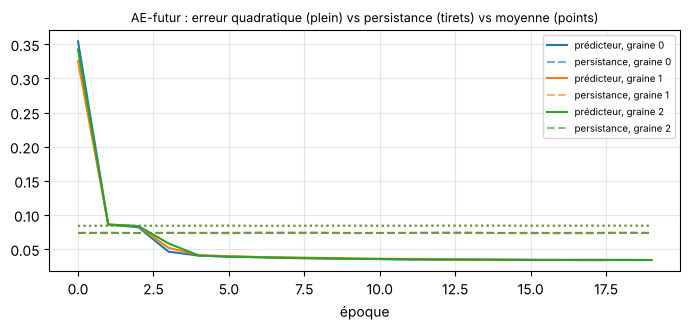

In [7]:
if HIST:
    fig, ax = plt.subplots(figsize=(7, 3.4))
    for s_, h in HIST.items():
        h = np.array(h); ax.plot(h[:, 0], color=f"C{s_}", label=f"prédicteur, graine {s_}")
        ax.plot(h[:, 1], color=f"C{s_}", ls="--", alpha=0.6, label=f"persistance, graine {s_}"); ax.plot(h[:, 2], color=f"C{s_}", ls=":", alpha=0.6)
    ax.set_title("AE-futur : erreur quadratique (plein) vs persistance (tirets) vs moyenne (points)", fontsize=9); ax.set_xlabel("époque"); ax.legend(fontsize=7)
    plt.tight_layout(); plt.savefig(RES / "pretraining.png", dpi=90); plt.show()

## 6. Fine-tuning

Même procédure que dans `F-JEPA_600_evenements` : tête linéaire, 6 époques de 150 lots de 128 (« normal ») ou de 300 lots (« long »), meilleure époque en validation, probabilités lissées sur 24 h. Les fine-tunings de l'encodeur aléatoire, de JEPA-16 et de l'autoencodeur-16 sont repris de `results_600/fine_tuning.pkl`, ceux de JEPA-futur de `results_jepa_futur/fine_tuning.pkl` (mêmes fenêtres, mêmes graines, même code) ; seul AE-futur est fine-tuné ici (résultats enregistrés au fur et à mesure dans `fine_tuning.pkl`, reprise possible).

In [8]:
class Classifier(nn.Module):
    def __init__(self, enc):
        super().__init__(); self.enc = enc; self.head = nn.Sequential(nn.LayerNorm(192), nn.Linear(192, 1))
    def forward(self, x, w):
        z = self.enc(x)
        return self.head(torch.cat([(z * w).sum(1) / (w.sum(1) + 1e-6), z[:, -16:].mean(1)], 1))[:, 0]

E_IDX = np.array([(ALL.index(m), e - WIN) for m, e in zip(E.machine, E.tok_end)])
def smooth_rows(p, rows):
    return pd.Series(p, index=E.index[rows]).groupby(E.machine.to_numpy()[rows]).transform(lambda x: x.ewm(span=12).mean()).to_numpy()

@torch.inference_mode()
def predict_rows(model, rows, B=512):
    model.eval(); out = []
    for i in range(0, len(rows), B):
        idx = E_IDX[rows[i:i + B]]; out.append(model(batch_from(idx), batch_w(idx)).numpy())
    return np.concatenate(out)

def finetune(enc_state, seed, tr_mask, va_mask, epochs=FT_EPOCHS, steps=FT_STEPS, B=128):
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    enc = Encoder(D_TOK)
    if enc_state is not None: enc.load_state_dict(enc_state)
    model = Classifier(enc)
    opt = torch.optim.AdamW([{"params": model.enc.parameters(), "lr": 2e-4}, {"params": model.head.parameters(), "lr": 1e-3}], weight_decay=0.05)
    tr_rows, va_rows = np.flatnonzero(tr_mask), np.flatnonzero(va_mask)
    yt_ = torch.tensor(yE, dtype=torch.float32); best = (-1, None, 0)
    for ep in range(epochs):
        model.train()
        for _ in range(steps):
            r_ = rng.choice(tr_rows, B); idx = E_IDX[r_]
            loss = F.binary_cross_entropy_with_logits(model(batch_from(idx), batch_w(idx)), yt_[r_])
            opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
        auc_v = roc_auc_score(yE[va_rows], smooth_rows(predict_rows(model, va_rows), va_rows))
        if auc_v > best[0]: best = (auc_v, {k: v.clone() for k, v in model.state_dict().items()}, ep + 1)
    model.load_state_dict(best[1]); all_rows = np.arange(len(E)); raw = predict_rows(model, all_rows)
    return smooth_rows(raw, all_rows).astype(np.float32), best[0], best[2], raw.astype(np.float32)

def pad(p, msk):
    out = np.full(len(E), np.nan, np.float32); out[msk] = p; return out

old = pickle.load(open(RES_600 / "fine_tuning.pkl", "rb"))
assert old["_config"] == CONFIG_FT and len(old[("JEPA-16", "600", SEEDS[0], FT_STEPS)][0]) == len(E), "results_600 doit venir du même protocole"
FT_ROWS = []
for (name, k, s_, steps), v in [(k_, v_) for k_, v_ in old.items() if k_ != "_config"]:
    if s_ in SEEDS:
        SCORES[(f"{name} fine-tuné" + (" long" if steps == FT_STEPS_LONG else ""), k, s_)] = v[0]
        FT_ROWS.append(dict(encodeur=f"{name} ({steps} lots/époque)", graine=s_, auc_validation=v[1], epoque=v[2]))
del old
jf = pickle.load(open(RES_JF / "fine_tuning.pkl", "rb")); assert jf["_config"] == dict(CONFIG_FT, pre=CONFIG_PRE)
for (name, k, s_, steps), v in [(k_, v_) for k_, v_ in jf.items() if k_ != "_config"]:
    if s_ in SEEDS:
        SCORES[(f"{name} fine-tuné" + (" long" if steps == FT_STEPS_LONG else ""), k, s_)] = v[0]
        FT_ROWS.append(dict(encodeur=f"{name} ({steps} lots/époque)", graine=s_, auc_validation=v[1], epoque=v[2]))
del jf

ft_file = RES / "fine_tuning.pkl"
FT = pickle.load(open(ft_file, "rb")) if ft_file.exists() else {}
if FT.get("_config") != dict(CONFIG_FT, pre=CONFIG_PRE): FT = {"_config": dict(CONFIG_FT, pre=CONFIG_PRE)}
for steps in (FT_STEPS, FT_STEPS_LONG):
    for s_ in SEEDS:
        key = (NEW, "600", s_, steps)
        if key not in FT:
            t1 = time.time()
            p, a, ep_, raw = finetune(STATES[(NEW, s_)], s_, TR["600"], VA["600"], steps=steps)
            FT[key] = (p, a, ep_, raw); pickle.dump(FT, open(ft_file, "wb"))
            print(f"{NEW} {steps} lots/époque, graine {s_} : AUC validation {a:.3f} (époque {ep_}), {time.time() - t1:.0f} s", flush=True)
        SCORES[(f"{NEW} fine-tuné" + (" long" if steps == FT_STEPS_LONG else ""), "600", s_)] = FT[key][0]
        FT_ROWS.append(dict(encodeur=f"{NEW} ({steps} lots/époque)", graine=s_, auc_validation=FT[key][1], epoque=FT[key][2]))
print(f"fine-tuning terminé ({(time.time() - t_start) / 60:.0f} min écoulées)")
pd.DataFrame(FT_ROWS).pivot_table(index="encodeur", columns="graine", values=["auc_validation", "epoque"]).round(3)

AE-futur 150 lots/époque, graine 0 : AUC validation 0.762 (époque 6), 841 s


AE-futur 150 lots/époque, graine 1 : AUC validation 0.769 (époque 6), 865 s


AE-futur 150 lots/époque, graine 2 : AUC validation 0.760 (époque 6), 783 s


AE-futur 300 lots/époque, graine 0 : AUC validation 0.780 (époque 5), 1066 s


AE-futur 300 lots/époque, graine 1 : AUC validation 0.780 (époque 6), 1028 s


AE-futur 300 lots/époque, graine 2 : AUC validation 0.784 (époque 5), 953 s


fine-tuning terminé (144 min écoulées)


auc_validation               epoque          
graine                                         0      1      2      0    1    2
encodeur                                                                       
AE-futur (150 lots/époque)                 0.762  0.769  0.760    6.0  6.0  6.0
AE-futur (300 lots/époque)                 0.780  0.780  0.784    5.0  6.0  5.0
Aléatoire (150 lots/époque)                0.769  0.768  0.774    6.0  6.0  6.0
Aléatoire (300 lots/époque)                0.781  0.781  0.785    6.0  6.0  6.0
Autoencodeur-16 (150 lots/époque)          0.768  0.764  0.759    6.0  6.0  6.0
JEPA-16 (150 lots/époque)                  0.761  0.773  0.777    6.0  6.0  6.0
JEPA-16 (300 lots/époque)                  0.782  0.788  0.790    5.0  5.0  4.0
JEPA-futur (150 lots/époque)               0.750  0.751  0.761    6.0  6.0  6.0
JEPA-futur (300 lots/époque)               0.774  0.761  0.778    5.0  6.0  6.0

## 7. Sondes sur l'encodeur gelé

Même représentation et même sonde logistique qu'avant ; sondes de l'encodeur aléatoire et de JEPA-16 reprises de `results_600/sondes.pkl`, celles de JEPA-futur de `results_jepa_futur/sondes.pkl`.

In [9]:
S_IDX = np.array([(ALL.index(m), e - WIN) for m, e in zip(S.machine, S.tok_end)])
@torch.inference_mode()
def embed(state):
    enc = Encoder(D_TOK); enc.load_state_dict(state); enc.eval(); out = []
    for i in range(0, len(S_IDX), 512):
        ii = S_IDX[i:i + 512]; z = enc(batch_from(ii)); w = batch_w(ii)
        out.append(torch.cat([z.mean(1), (z * w).sum(1) / (w.sum(1) + 1e-6), z[:, -16:].mean(1)], 1).numpy())
    return np.concatenate(out)

def probe_features(emb):
    out = []; sm = S.machine.to_numpy(); rf = ref.to_numpy(); ev_ = S["eval"].to_numpy()
    for m in ALL:
        mm = sm == m; Zm = pd.DataFrame(emb[mm]); r_ = rf[mm]
        Zm = (Zm - Zm[r_].mean()) / (Zm[r_].std() + 1e-9)
        out.append(np.hstack([Zm.to_numpy(), Zm.ewm(span=12, ignore_na=True).mean().to_numpy()])[ev_[mm]].astype(np.float32))
    return np.nan_to_num(np.vstack(out))

for (name, s_), p_ in pickle.load(open(RES_600 / "sondes.pkl", "rb")).items():
    if s_ in SEEDS: SCORES[(f"{name} sonde", "600", s_)] = p_
for s_, p_ in pickle.load(open(RES_JF / "sondes.pkl", "rb")).items():
    if s_ in SEEDS: SCORES[(f"{JF} sonde", "600", s_)] = p_
probe_file = RES / "sondes.pkl"
PR = pickle.load(open(probe_file, "rb")) if probe_file.exists() else {}
if PR.get("_config") != CONFIG_PRE: PR = {"_config": CONFIG_PRE}
for s_ in SEEDS:
    if s_ not in PR:
        t1 = time.time(); Zf = probe_features(embed(STATES[(NEW, s_)]))
        p_, hp, a = fit_select(lr_grid, Zf, TR["600"], VA["600"]); PR[s_] = p_.astype(np.float32)
        del Zf; pickle.dump(PR, open(probe_file, "wb"))
        print(f"{NEW} graine {s_} : {hp}, AUC validation {a:.3f} ({time.time() - t1:.0f} s)", flush=True)
    SCORES[(f"{NEW} sonde", "600", s_)] = PR[s_]

AE-futur graine 0 : C=1.0, AUC validation 0.689 (777 s)


AE-futur graine 1 : C=1.0, AUC validation 0.710 (593 s)


AE-futur graine 2 : C=1.0, AUC validation 0.705 (580 s)


## 8. Surprise du prédicteur (sans étiquette)

Comme dans `F-JEPA_jepa_futur`, pour JEPA-futur et AE-futur : pour chaque fenêtre de test se terminant à *t*, le prédicteur lit les 3 jours qui se terminent à *t* − 2 jours et on mesure l'écart entre sa prévision et les 2 derniers jours réellement observés (cible latente pour JEPA-futur, tokens bruts pour AE-futur). **Surprise** = écart brut ; **surprise relative** = écart du prédicteur moins écart de la persistance. Lissés sur 24 h, test M1–M16 seulement.

In [10]:
TEST0 = tok_of(VAL_END)
@torch.inference_mode()
def surprise(kind, st, m):
    enc, tgt, pred = load_models(kind, st); L = crit(kind)
    ends = np.arange(TEST0 - (ND + 1) * WIN - ((TEST0 - (ND + 1) * WIN) % STRIDE), len(TOK[m]) + 1, STRIDE); ends = ends[ends >= WIN]
    mi = ALL.index(m); Zo, Zt = [], []
    for i in range(0, len(ends), 512):
        x = batch_from([(mi, e - WIN) for e in ends[i:i + 512]])
        Zo.append(seg_pool(enc(x))); Zt.append(target_of(kind, tgt, x))
    Zo, Zt = torch.cat(Zo), torch.cat(Zt); pos = {e: i for i, e in enumerate(ends)}
    rows = np.flatnonzero(TE["M1–M16"] & (E.machine == m).to_numpy()); e_ = E.tok_end.to_numpy()[rows]
    ix = lambda k: torch.as_tensor([pos[e - k * WIN] for e in e_])
    ctx = torch.cat([Zo[ix(k)] for k in range(ND - 1, FUT_DAYS - 1, -1)], 1)                  # jours finissant à t−4j, t−3j, t−2j
    fut = torch.cat([Zt[ix(k)] for k in range(FUT_DAYS - 1, -1, -1)], 1)                      # jours finissant à t−1j, t
    last = Zt[ix(FUT_DAYS)].repeat(1, FUT_DAYS, 1)
    err = L(pred(ctx), fut, reduction="none").mean((1, 2)).numpy()
    err_p = L(last, fut, reduction="none").mean((1, 2)).numpy()
    return rows, err, err - err_p

te = np.flatnonzero(TE["M1–M16"])
for name in (JF, NEW):
    for s_ in SEEDS:
        t1 = time.time(); sa, sb = np.full(len(E), np.nan, np.float32), np.full(len(E), np.nan, np.float32)
        for m in M16:
            rows, a_, b_ = surprise(KIND[name], PRE_ST[(name, s_)], m); sa[rows] = a_; sb[rows] = b_
        SCORES[(f"{name} surprise", "600", s_)] = pad(smooth_rows(sa[te], te), TE["M1–M16"])
        SCORES[(f"{name} surprise relative", "600", s_)] = pad(smooth_rows(sb[te], te), TE["M1–M16"])
        print(f"surprise {name} graine {s_} : {time.time() - t1:.0f} s", flush=True)

surprise JEPA-futur graine 0 : 64 s


surprise JEPA-futur graine 1 : 61 s


surprise JEPA-futur graine 2 : 64 s


surprise AE-futur graine 0 : 35 s


surprise AE-futur graine 1 : 36 s


surprise AE-futur graine 2 : 35 s


## 9. Résultats sur le test (sept. 2025 → août 2026)

ROC-AUC sur trois tests. Réseaux : **ensemble** des 3 graines (moyenne des rangs) et **moyenne des AUC par graine** (un modèle seul, ce qu'on déploierait sans ensemble). Intervalle à 95 % par bootstrap par blocs (machine × semaine) pour l'ensemble. Une case vide = pas de prédiction sur ce test (surprise : M1–M16 seulement).

In [11]:
def rank(x): return pd.Series(x).rank(pct=True).to_numpy()
rngb = np.random.default_rng(0); BOOT = {}
for tn, msk in TE.items():
    Et = E[msk]; blocks = (Et.machine + "_" + Et.time.dt.strftime("%G-%V")).to_numpy()
    ub, inv = np.unique(blocks, return_inverse=True); bidx = [np.flatnonzero(inv == i) for i in range(len(ub))]
    BOOT[tn] = [np.concatenate([bidx[b] for b in rngb.integers(0, len(ub), len(ub))]) for _ in range(300)]
def auc_on(p, tn): return roc_auc_score(yE[TE[tn]], p[TE[tn]])
def available(meth, tn):
    p = SCORES.get((meth, "600", None), SCORES.get((meth, "600", SEEDS[0])))
    return p is not None and not np.isnan(p[TE[tn]]).any()

rows = []
for meth in sorted({k[0] for k in SCORES}):
    for tn in TE:
        if not available(meth, tn): continue
        if (meth, "600", None) in SCORES: p = SCORES[(meth, "600", None)]; per = []
        else: p = np.mean([rank(SCORES[(meth, "600", s_)]) for s_ in SEEDS], 0); per = [auc_on(SCORES[(meth, "600", s_)], tn) for s_ in SEEDS]
        sc, yt = p[TE[tn]], yE[TE[tn]]; bs = [roc_auc_score(yt[i], sc[i]) for i in BOOT[tn]]
        rows.append(dict(methode=meth, test=tn, roc_auc=roc_auc_score(yt, sc), ic95_bas=np.percentile(bs, 2.5), ic95_haut=np.percentile(bs, 97.5),
                         pr_auc=average_precision_score(yt, sc), moyenne_graines=np.mean(per) if per else roc_auc_score(yt, sc), par_graine=" / ".join(f"{x:.3f}" for x in per)))
RESULTS = pd.DataFrame(rows); RESULTS.to_csv(RES / "metriques.csv", index=False)
for tn in TE: print(f"test {tn} : {TE[tn].sum():,} fenêtres, {yE[TE[tn]].mean():.1%} positives")
TAB = RESULTS[RESULTS.test == "M1–M16"].set_index("methode")[["moyenne_graines", "par_graine", "roc_auc", "ic95_bas", "ic95_haut", "pr_auc"]]
TAB.sort_values("moyenne_graines", ascending=False).round(3)

test M1–M4 : 10,636 fenêtres, 20.1% positives
test M1–M16 : 43,854 fenêtres, 18.4% positives
test M1–M37 : 101,000 fenêtres, 17.6% positives


,moyenne_graines,par_graine,roc_auc,ic95_bas,ic95_haut,pr_auc
methode,,,,,,
JEPA-16 fine-tuné long,0.801,0.797 / 0.802 / 0.805,0.810,0.776,0.843,0.695
Aléatoire fine-tuné long,0.797,0.791 / 0.797 / 0.802,0.805,0.765,0.837,0.684
AE-futur fine-tuné long,0.796,0.792 / 0.796 / 0.801,0.803,0.768,0.837,0.667
JEPA-16 fine-tuné,0.789,0.788 / 0.785 / 0.794,0.801,0.765,0.832,0.664
Autoencodeur-16 fine-tuné,0.789,0.786 / 0.784 / 0.796,0.800,0.766,0.831,0.651
JEPA-futur fine-tuné long,0.789,0.788 / 0.786 / 0.793,0.801,0.765,0.834,0.675
AE-futur fine-tuné,0.788,0.781 / 0.796 / 0.787,0.799,0.762,0.831,0.642
Aléatoire fine-tuné,0.784,0.789 / 0.784 / 0.777,0.795,0.759,0.823,0.653
JEPA-futur fine-tuné,0.769,0.762 / 0.762 / 0.782,0.786,0.750,0.816,0.629


Moyenne des AUC par graine, sur les trois tests :

In [12]:
RESULTS.pivot_table(index="methode", columns="test", values="moyenne_graines").round(3).sort_values("M1–M16", ascending=False)

test,M1–M16,M1–M37,M1–M4
methode,,,
JEPA-16 fine-tuné long,0.801,0.804,0.834
Aléatoire fine-tuné long,0.797,0.802,0.828
AE-futur fine-tuné long,0.796,0.795,0.833
JEPA-futur fine-tuné long,0.789,0.791,0.818
Autoencodeur-16 fine-tuné,0.789,0.788,0.810
JEPA-16 fine-tuné,0.789,0.787,0.814
AE-futur fine-tuné,0.788,0.784,0.819
Aléatoire fine-tuné,0.784,0.786,0.804
JEPA-futur fine-tuné,0.769,0.770,0.775


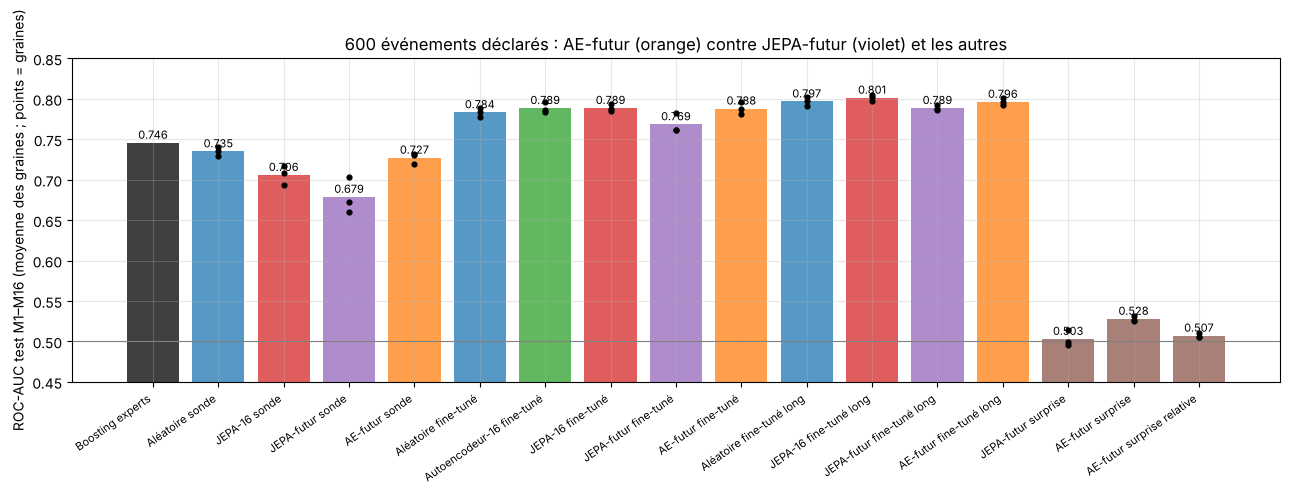

In [13]:
JFF, AF, J, A, AE, BO = f"{JF} fine-tuné", f"{NEW} fine-tuné", "JEPA-16 fine-tuné", "Aléatoire fine-tuné", "Autoencodeur-16 fine-tuné", "Boosting experts"
order = [("Boosting experts", "k"), ("Aléatoire sonde", "C0"), ("JEPA-16 sonde", "C3"), (f"{JF} sonde", "C4"), (f"{NEW} sonde", "C1"),
         (A, "C0"), (AE, "C2"), (J, "C3"), (JFF, "C4"), (AF, "C1"),
         (A + " long", "C0"), (J + " long", "C3"), (JFF + " long", "C4"), (AF + " long", "C1"),
         (f"{JF} surprise", "C5"), (f"{NEW} surprise", "C5"), (f"{NEW} surprise relative", "C5")]
fig, ax = plt.subplots(figsize=(13, 4.8)); r16 = RESULTS[RESULTS.test == "M1–M16"].set_index("methode")
for i, (meth, c) in enumerate(order):
    r_ = r16.loc[meth]; ax.bar(i, r_.moyenne_graines, color=c, alpha=0.75)
    if r_.par_graine: ax.scatter([i] * len(SEEDS), [float(x) for x in r_.par_graine.split(" / ")], color="k", s=12, zorder=3)
    ax.text(i, r_.moyenne_graines + 0.005, f"{r_.moyenne_graines:.3f}", ha="center", fontsize=8)
ax.set_xticks(range(len(order))); ax.set_xticklabels([m for m, _ in order], rotation=35, ha="right", fontsize=8)
ax.set_ylim(0.45, 0.85); ax.axhline(0.5, color="grey", lw=0.8); ax.set_ylabel("ROC-AUC test M1–M16 (moyenne des graines ; points = graines)")
ax.set_title("600 événements déclarés : AE-futur (orange) contre JEPA-futur (violet) et les autres")
plt.tight_layout(); plt.savefig(RES / "comparaison.png", dpi=90); plt.show()

### 9.1 Écarts appariés

Écart d'AUC entre deux méthodes (moyenne des AUC des 3 graines), intervalle à 95 % par bootstrap par blocs avec **les mêmes blocs pour les deux méthodes**, et écart graine par graine.

In [14]:
def preds(meth, tn): return [SCORES[(meth, "600", None)][TE[tn]]] if (meth, "600", None) in SCORES else [SCORES[(meth, "600", s_)][TE[tn]] for s_ in SEEDS]
def auc_mean(ps, tn, idx=None):
    yt = yE[TE[tn]]; return np.mean([roc_auc_score(yt, p_) if idx is None else roc_auc_score(yt[idx], p_[idx]) for p_ in ps])
def ecart_graines(a, b, tn):
    d = [auc_on(SCORES[(a, "600", s_)], tn) - auc_on(SCORES.get((b, "600", None), SCORES.get((b, "600", s_))), tn) for s_ in SEEDS]
    return dict(moyenne=np.mean(d), par_graine=" / ".join(f"{x:+.3f}" for x in d), positives=sum(x > 0 for x in d))
def apparie(tn, a, b):
    Pa, Pb = preds(a, tn), preds(b, tn); f = lambda idx: auc_mean(Pa, tn, idx) - auc_mean(Pb, tn, idx)
    bs = np.array([f(i) for i in BOOT[tn]])
    return dict(test=tn, comparaison=f"{a} − {b}", ecart=f(None), ic95_bas=np.percentile(bs, 2.5), ic95_haut=np.percentile(bs, 97.5),
                part_bootstrap_positive=(bs > 0).mean(), par_graine=ecart_graines(a, b, tn)["par_graine"])
COMP = [("M1–M16", AF, JFF), ("M1–M16", AF, A), ("M1–M16", AF, AE), ("M1–M16", AF, J), ("M1–M16", AF, BO),
        ("M1–M16", AF + " long", JFF + " long"), ("M1–M16", AF + " long", A + " long"), ("M1–M16", AF + " long", J + " long"), ("M1–M16", AF + " long", AF),
        ("M1–M16", f"{NEW} sonde", f"{JF} sonde"), ("M1–M16", f"{NEW} sonde", "Aléatoire sonde"), ("M1–M16", f"{NEW} sonde", "JEPA-16 sonde"),
        (TALL, AF, JFF), (TALL, AF, A), (TALL, AF + " long", J + " long")]
APP = pd.DataFrame([apparie(*c) for c in COMP]); APP.to_csv(RES / "ecarts_apparies.csv", index=False)
APP.round(3)

,test,comparaison,ecart,ic95_bas,ic95_haut,part_bootstrap_positive,par_graine
0,M1–M16,AE-futur fine-tuné − JEPA-futur fine-tuné,0.019,0.005,0.033,0.997,+0.019 / +0.034 / +0.005
1,M1–M16,AE-futur fine-tuné − Aléatoire fine-tuné,0.005,-0.006,0.018,0.783,-0.008 / +0.012 / +0.010
2,M1–M16,AE-futur fine-tuné − Autoencodeur-16 fine-tuné,-0.001,-0.011,0.010,0.473,-0.005 / +0.012 / -0.009
3,M1–M16,AE-futur fine-tuné − JEPA-16 fine-tuné,-0.001,-0.012,0.010,0.430,-0.007 / +0.011 / -0.007
4,M1–M16,AE-futur fine-tuné − Boosting experts,0.042,0.012,0.070,0.997,+0.035 / +0.050 / +0.041
5,M1–M16,AE-futur fine-tuné long − JEPA-futur fine-tuné...,0.008,-0.001,0.017,0.947,+0.004 / +0.011 / +0.008
6,M1–M16,AE-futur fine-tuné long − Aléatoire fine-tuné ...,-0.000,-0.010,0.010,0.453,+0.001 / -0.001 / -0.001
7,M1–M16,AE-futur fine-tuné long − JEPA-16 fine-tuné long,-0.005,-0.014,0.004,0.143,-0.005 / -0.006 / -0.004
8,M1–M16,AE-futur fine-tuné long − AE-futur fine-tuné,0.008,-0.001,0.017,0.967,+0.011 / +0.000 / +0.014
9,M1–M16,AE-futur sonde − JEPA-futur sonde,0.048,0.032,0.067,1.000,+0.060 / +0.060 / +0.026


### 9.2 Par type de dégradation (test M1–M16)

ROC-AUC des fenêtres positives d'un type contre toutes les fenêtres négatives du test (réseaux : ensemble des graines).

In [15]:
tn = "M1–M16"; yt = yE[TE[tn]]; neg = yt == 0; typ = E.type_suivant.to_numpy()[TE[tn]]; rows = []
for meth in [BO, A, AE, J, JFF, AF, A + " long", J + " long", JFF + " long", AF + " long", f"{NEW} surprise"]:
    p = SCORES[(meth, "600", None)] if (meth, "600", None) in SCORES else np.mean([rank(SCORES[(meth, "600", s_)]) for s_ in SEEDS], 0)
    sc = p[TE[tn]]; row = {"methode": meth}
    for ft in TYPES:
        pos = (yt == 1) & (typ == ft)
        row[ft] = roc_auc_score(np.r_[np.ones(pos.sum()), np.zeros(neg.sum())], np.r_[sc[pos], sc[neg]]) if pos.sum() else np.nan
    rows.append(row)
pd.DataFrame(rows).set_index("methode").round(3)

,refroidissement,roulement,courroie,pneumatique,electrique
methode,,,,,
Boosting experts,0.674,0.898,0.786,0.912,0.468
Aléatoire fine-tuné,0.861,0.869,0.849,0.888,0.480
Autoencodeur-16 fine-tuné,0.899,0.816,0.856,0.888,0.504
JEPA-16 fine-tuné,0.879,0.861,0.842,0.899,0.493
JEPA-futur fine-tuné,0.834,0.832,0.849,0.882,0.510
AE-futur fine-tuné,0.890,0.829,0.835,0.883,0.522
Aléatoire fine-tuné long,0.886,0.869,0.854,0.899,0.483
JEPA-16 fine-tuné long,0.886,0.880,0.854,0.901,0.500
JEPA-futur fine-tuné long,0.893,0.851,0.850,0.892,0.482


## 10. Hypothèses et conclusions

Hypothèses écrites **avant** l'exécution (en tête du notebook), confrontées ici sans les réécrire.

In [16]:
def R(meth, tn="M1–M16"):
    r_ = RESULTS[(RESULTS.methode == meth) & (RESULTS.test == tn)]; assert len(r_) == 1, (meth, tn); return r_.iloc[0]
n_ = len(SEEDS); ok = []
for suf in ["", " long"]:
    a_, b_ = R(AF + suf).moyenne_graines, R(JFF + suf).moyenne_graines; ok.append(a_ > b_)
    print(f"H22 : fine-tuning{suf or ' normal'} : {NEW} {a_:.3f} contre {JF} {b_:.3f} ({a_ - b_:+.3f})")
print(f"H22 -> {'confirmée' if all(ok) else 'non confirmée'}")
h = ecart_graines(AF, A, "M1–M16")
print(f"H23 : {AF} − {A} = {h['moyenne']:+.3f} (par graine {h['par_graine']}) -> {'confirmée' if h['positives'] == n_ else 'non confirmée'}")
sa_, sj_, sr_ = R(f"{NEW} sonde").moyenne_graines, R(f"{JF} sonde").moyenne_graines, R("Aléatoire sonde").moyenne_graines
print(f"H24 : sondes gelées {NEW} {sa_:.3f} | {JF} {sj_:.3f} | aléatoire {sr_:.3f} -> {'confirmée' if sa_ > max(sj_, sr_) else 'non confirmée'}")
a_, b_ = R(AF).moyenne_graines, R(AE).moyenne_graines
print(f"H25 : {NEW} fine-tuné {a_:.3f} contre autoencodeur-16 fine-tuné {b_:.3f} ({a_ - b_:+.3f}) -> {'confirmée' if a_ > b_ else 'non confirmée'}")
s1, s2 = R(f"{NEW} surprise").moyenne_graines, R(f"{NEW} surprise relative").moyenne_graines
print(f"H26 : surprise {s1:.3f} ; surprise relative {s2:.3f} -> {'confirmée' if max(s1, s2) >= 0.55 else 'non confirmée'}")
print(f"Références : boosting {R(BO).roc_auc:.3f} ; JEPA-16 long {R(J + ' long').moyenne_graines:.3f} ; aléatoire long {R(A + ' long').moyenne_graines:.3f}")
print(f"Durée totale : {(time.time() - t_start) / 60:.0f} min")

H22 : fine-tuning normal : AE-futur 0.788 contre JEPA-futur 0.769 (+0.019)
H22 : fine-tuning long : AE-futur 0.796 contre JEPA-futur 0.789 (+0.008)
H22 -> confirmée
H23 : AE-futur fine-tuné − Aléatoire fine-tuné = +0.005 (par graine -0.008 / +0.012 / +0.010) -> non confirmée
H24 : sondes gelées AE-futur 0.727 | JEPA-futur 0.679 | aléatoire 0.735 -> non confirmée
H25 : AE-futur fine-tuné 0.788 contre autoencodeur-16 fine-tuné 0.789 (-0.001) -> non confirmée
H26 : surprise 0.528 ; surprise relative 0.507 -> non confirmée
Références : boosting 0.746 ; JEPA-16 long 0.801 ; aléatoire long 0.797
Durée totale : 195 min


### 10.1 Conclusions (rédigées après exécution, données SYNTHÉTIQUES)

**Pour prédire le futur, l'autoencodeur fait mieux que JEPA, mais pas mieux que l'absence de pré-entraînement.** H22 est confirmée ; H23 à H26 ne le sont pas.

- **Le pré-entraînement fonctionne** : sur la période de validation, AE-futur divise par 2 l'erreur de la persistance (gain de 53 %, contre 25 à 46 % pour JEPA-futur), de façon très stable d'une graine à l'autre.
- **AE-futur contre JEPA-futur (H22)** : +0,019 [+0,005 ; +0,033] au fine-tuning normal (0,788 contre 0,769, positif pour les 3 graines) et +0,008 au fine-tuning long (0,796 contre 0,789). Encodeur gelé : sonde AE-futur 0,727 contre 0,679. Viser les tokens bruts plutôt que les représentations latentes évite donc la dégradation observée avec JEPA-futur.
- **AE-futur contre l'encodeur aléatoire (H23)** : +0,005 [−0,006 ; +0,018] au fine-tuning normal (une graine sur trois négative), 0,000 au fine-tuning long (0,796 contre 0,797). Sonde gelée : 0,727 contre 0,735. Pas de gain mesurable.
- **AE-futur contre les blocs intérieurs** : au même niveau que l'autoencodeur-16 et JEPA-16 au fine-tuning normal (0,788 contre 0,789), un peu en dessous de JEPA-16 au fine-tuning long (0,796 contre 0,801, −0,005 [−0,014 ; +0,004]).
- **Surprise sans étiquette** : 0,528, la seule surprise un peu au-dessus du hasard, mais sous le seuil de 0,55 fixé à l'avance.
- Tous les réseaux fine-tunés restent nettement au-dessus du boosting expert (0,746).

**Interprétation.** Les tokens bruts contiennent explicitement les écarts-types et la forme de chaque quart d'heure ; en les reconstruisant, l'encodeur garde une trace des dynamiques fines, alors que la cible latente de JEPA-futur s'est surtout calée sur le régime de marche, lent et persistant. Mais dans les deux cas, avec 600 événements étiquetés, un encodeur aléatoire bien fine-tuné obtient le même résultat : le pré-entraînement ne sert pas ici, quel que soit son objectif (blocs intérieurs ou jours suivants, latent ou brut).
